# FinanceGuard — Predicción de Churn Bancario
## Notebook 3: Aprendizaje No Supervisado

**Autor:** Mauricio Melgarejo


## 1. Importación de librerías

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering
from sklearn.cluster import KMeans, DBSCAN

# Reducción de dimensionalidad
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Preprocesamiento y métricas
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Configuración visual
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

print('Librerías importadas correctamente')

Librerías importadas correctamente


## 2. Carga y preparación de datos

In [2]:
# Cargar el dataset
df = pd.read_csv('Churn_Modelling.csv')

# Eliminar columnas que no aportan información para predecir churn
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Convertir variables categóricas a numéricas
df_encoded = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

# Separar features y target
# El target no se usa para clustering pero se guarda para analizar los grupos después
X = df_encoded.drop(columns='Exited')
y = df_encoded['Exited']

# Escalar todas las variables — no hay train/test split en aprendizaje no supervisado
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Datos listos: {X_scaled.shape}')

Datos listos: (10000, 11)


## 3. K-Means Clustering

K-Means agrupa los 10.000 clientes por similitud en sus características sin usar la variable Exited. No sabe quién abandonó ni quién se quedó.
Después de formar los grupos miramos cuánto churn tiene cada uno para entender qué tipo de cliente tiene mayor riesgo.

### 3.1 Elbow Method

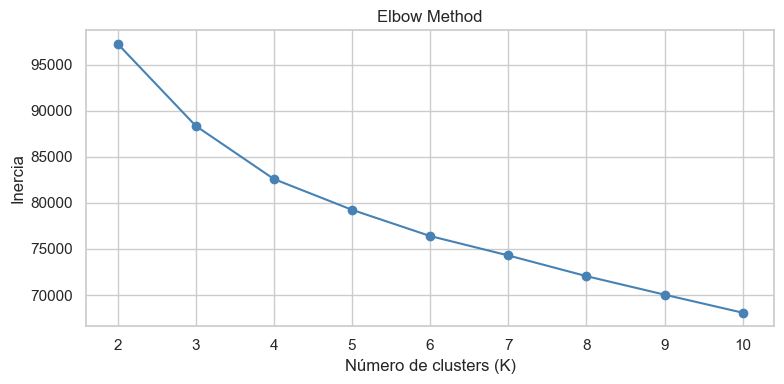

In [3]:
# Probar K-Means con diferentes valores de K para encontrar el número óptimo de clusters
# La inercia mide qué tan compactos son los grupos — menor es mejor
inercias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)

# Graficar la curva de inercia para identificar el codo
plt.figure(figsize=(8, 4))
plt.plot(K_range, inercias, marker='o', color='steelblue')
plt.title('Elbow Method')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.xticks(K_range)
plt.tight_layout()
plt.show()

El gráfico muestra que la inercia baja gradualmente de K=2 a K=10 
sin un codo claramente marcado. Eso significa que no hay un número 
de clusters obvio solo mirando este gráfico.

Usamos el Silhouette Score para confirmar el K óptimo con un número concreto.

### 3.2 Silhouette Score

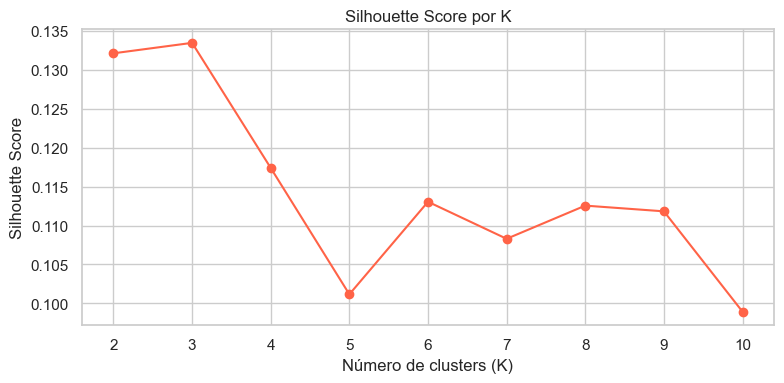

Mejor K según Silhouette Score: 3


In [4]:
# Calcular Silhouette Score para cada valor de K
# Valores cercanos a 1 indican clusters bien separados
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Graficar los scores para identificar el K óptimo
plt.figure(figsize=(8, 4))
plt.plot(K_range, silhouette_scores, marker='o', color='tomato')
plt.title('Silhouette Score por K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(K_range)
plt.tight_layout()
plt.show()

# Seleccionar el K con mayor score
mejor_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f'Mejor K según Silhouette Score: {mejor_k}')

El gráfico muestra el Silhouette Score para cada valor de K.
Un score cercano a 1 indica clusters bien separados, cercano a 0 indica solapamiento.

K=3 obtuvo el score más alto de 0.134 — un valor bajo pero el mejor disponible.
Esto indica que los grupos tienen solapamiento, lo cual es esperable 
con 11 variables y datos de clientes bancarios.

Combinando Elbow Method y Silhouette Score, seleccionamos K=3.

### 3.3 K-Means con K=3

In [5]:
# Entrenar K-Means con K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)

# Guardar los clusters en el dataframe para análisis posterior
df_encoded['Cluster_KMeans'] = clusters_kmeans

# Mostrar distribución de clientes por cluster
print('Distribución de clientes por cluster:')
print(df_encoded['Cluster_KMeans'].value_counts().sort_index())

Distribución de clientes por cluster:
Cluster_KMeans
0    2509
1    5014
2    2477
Name: count, dtype: int64


K-Means dividió los 10.000 clientes en 3 grupos:
- Cluster 0: 2.509 clientes (25%)
- Cluster 1: 5.014 clientes (50%) — el grupo más grande
- Cluster 2: 2.477 clientes (25%)

El siguiente paso es ver cuánto churn tiene cada grupo para identificar cuál representa mayor riesgo para el banco.

Tasa de churn por cluster:
Cluster_KMeans
0    32.4
1    16.2
2    16.7
Name: Exited, dtype: float64


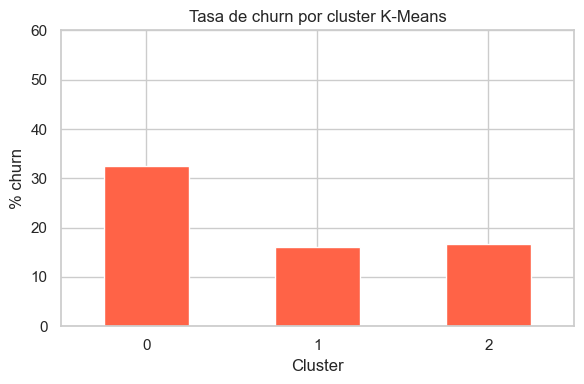

In [6]:
# Calcular tasa de churn por cluster para identificar segmentos de riesgo
churn_por_cluster = df_encoded.groupby('Cluster_KMeans')['Exited'].mean() * 100

print('Tasa de churn por cluster:')
print(churn_por_cluster.round(1))

# Visualizar la tasa de churn por cluster
plt.figure(figsize=(6, 4))
churn_por_cluster.plot(kind='bar', color='tomato', edgecolor='white')
plt.title('Tasa de churn por cluster K-Means')
plt.xlabel('Cluster')
plt.ylabel('% churn')
plt.ylim(0, 60)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

El gráfico muestra claramente la diferencia entre los 3 clusters.
El Cluster 0 tiene 32.4% de churn, el doble que los Clusters 1 y 2 que rondan el 16%.

Sin haber usado el churn para agrupar, K-Means identificó un segmento 
de alto riesgo solo por las características de los clientes.

El equipo de retención debería priorizar los 2.509 clientes del Cluster 0.

In [7]:
# Analizar las características promedio de cada cluster para entender qué tipo de cliente los compone
perfil = df_encoded.groupby('Cluster_KMeans')[
    ['CreditScore', 'Age', 'Tenure', 'Balance', 
     'NumOfProducts', 'IsActiveMember', 'EstimatedSalary']
].mean().round(2)

print('Perfil promedio por cluster:')
print(perfil)

Perfil promedio por cluster:
                CreditScore    Age  Tenure    Balance  NumOfProducts  \
Cluster_KMeans                                                         
0                    651.45  39.77    5.01  119730.12           1.52   
1                    649.67  38.51    5.00   62092.64           1.53   
2                    651.33  38.89    5.03   61818.15           1.54   

                IsActiveMember  EstimatedSalary  
Cluster_KMeans                                   
0                         0.50        101113.44  
1                         0.52         99899.18  
2                         0.53         99440.57  


Comparando el perfil de los 3 clusters, casi todas las variables son similares:
CreditScore, Age, Tenure, NumOfProducts, IsActiveMember y EstimatedSalary 
tienen valores muy parecidos entre los grupos.

La única variable que diferencia claramente al Cluster 0 es el Balance:
- **Cluster 0**: Balance promedio $119.730 → churn 32.4%
- **Cluster 1**: Balance promedio $62.092 → churn 16.2%
- **Cluster 2**: Balance promedio $61.818 → churn 16.7%

Los clientes con saldo alto son los que más abandonan.
Esto confirma lo encontrado en el EDA del Notebook 1: Balance era una 
de las variables más correlacionadas con el churn.
El equipo de retención debería priorizar los 2.509 clientes del Cluster 0.

### 4.1 Selección de epsilon — K-distancia

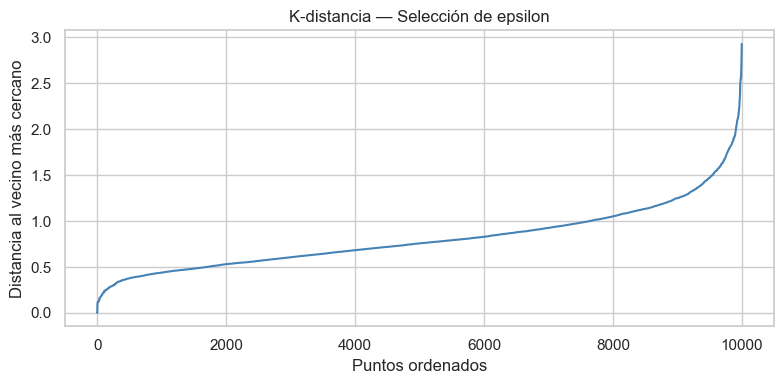

In [8]:
# Calcular distancia de cada punto a su vecino más cercano
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=2)
neighbors.fit(X_scaled)
distancias, _ = neighbors.kneighbors(X_scaled)

# Ordenar distancias de menor a mayor para visualizar el codo
distancias_sorted = np.sort(distancias[:, 1], axis=0)

# Graficar la curva para identificar el epsilon óptimo
plt.figure(figsize=(8, 4))
plt.plot(distancias_sorted, color='steelblue')
plt.title('K-distancia — Selección de epsilon')
plt.xlabel('Puntos ordenados')
plt.ylabel('Distancia al vecino más cercano')
plt.tight_layout()
plt.show()

El gráfico muestra la distancia de cada cliente a su vecino más cercano ordenada de menor a mayor.
Si hubiera un codo claro, ahí estaría el epsilon óptimo.

La curva sube gradualmente sin un quiebre claro. Esto significa que no hay zonas naturalmente densas en los datos: todos los clientes están a distancias similares entre sí. Con 11 variables esto es esperable y anticipa que DBSCAN va a tener dificultades para encontrar clusters bien definidos.

Se prueban distintos valores de epsilon basándose en el rango de distancias que muestra el gráfico (entre 0.2 y 0.5 para la mayoría de los puntos).

## 4. DBSCAN

In [9]:
# Primera prueba: eps=0.5 — límite superior del rango observado en el gráfico k-distancia
dbscan_05 = DBSCAN(eps=0.5, min_samples=5)
clusters_dbscan_05 = dbscan_05.fit_predict(X_scaled)

# Guardar resultados y mostrar distribución
df_encoded['Cluster_DBSCAN_05'] = clusters_dbscan_05

print('Distribución clusters DBSCAN eps=0.5:')
print(pd.Series(clusters_dbscan_05).value_counts().sort_index())
print(f'Clientes como ruido: {(clusters_dbscan_05 == -1).sum()}')

Distribución clusters DBSCAN eps=0.5:
-1     9921
 0        7
 1        7
 2        5
 3        5
 4        7
 5        7
 6        6
 7        5
 8        5
 9        5
 10       5
 11       5
 12       5
 13       5
Name: count, dtype: int64
Clientes como ruido: 9921


Con eps=0.5 casi todos los clientes (9.921) quedaron como ruido.

Solo se formaron 14 grupos de 5-7 clientes cada uno.

El radio de búsqueda es demasiado chico — se aumenta epsilon.

Se analiza el perfil de los clientes agrupados en la celda siguiente.

In [10]:
# Analizar las características de los clientes agrupados con eps=0.5
mascara_05 = clusters_dbscan_05 >= 0
clientes_05 = df_encoded[mascara_05][['CreditScore', 'Age', 'Tenure', 
                                      'Balance', 'NumOfProducts', 
                                      'IsActiveMember', 'EstimatedSalary',
                                      'Exited', 'Cluster_DBSCAN_05']]

# Mostrar cantidad agrupada y tasa de churn
print(f'Clientes agrupados: {mascara_05.sum()}')
print(f'Churn en agrupados: {clientes_05["Exited"].mean()*100:.1f}%')

# Mostrar perfil detallado por cluster
print()
print(clientes_05.sort_values('Cluster_DBSCAN_05').to_string())

Clientes agrupados: 79
Churn en agrupados: 2.5%

      CreditScore  Age  Tenure  Balance  NumOfProducts  IsActiveMember  EstimatedSalary  Exited  Cluster_DBSCAN_05
421           586   38       2      0.0              2               0         87168.46       0                  0
474           571   33       1      0.0              2               0        102750.70       0                  0
7314          588   36       2      0.0              2               0         92536.00       1                  0
4508          599   41       1      0.0              2               0         96069.82       0                  0
8532          585   35       2      0.0              2               0         98621.04       1                  0
8920          570   36       3      0.0              2               0         92118.75       0                  0
8581          585   43       2      0.0              2               0         89402.54       0                  0
1591          621   39       6 

Los 79 clientes agrupados comparten el mismo perfil:
- Balance = 0: no tienen saldo en su cuenta
- NumOfProducts = 2: tienen exactamente 2 productos contratados
- Churn 2.5% (2 de 79): muy bajo riesgo de abandono

DBSCAN con eps=0.5 encontró clientes casi idénticos entre sí.
Son clientes sin saldo y estables — no son prioridad para retención.

In [11]:
# Segunda prueba: eps=1.5 — se aumenta el radio al obtener demasiado ruido con eps=0.5
dbscan_15 = DBSCAN(eps=1.5, min_samples=5)
clusters_dbscan_15 = dbscan_15.fit_predict(X_scaled)

# Guardar resultados y mostrar distribución
df_encoded['Cluster_DBSCAN_15'] = clusters_dbscan_15

print('Distribución clusters DBSCAN eps=1.5:')
print(pd.Series(clusters_dbscan_15).value_counts().sort_index())
print(f'Clientes como ruido: {(clusters_dbscan_15 == -1).sum()}')

Distribución clusters DBSCAN eps=1.5:
-1     847
 0     380
 1      61
 2     153
 3     169
 4     212
 5     488
 6     481
 7     159
 8     340
 9     184
 10     83
 11    246
 12    384
 13    181
 14    156
 15    195
 16    231
 17    186
 18    189
 19     60
 20    108
 21    192
 22    159
 23    100
 24    153
 25    183
 26     87
 27    505
 28     62
 29     89
 30    259
 31    272
 32    230
 33     60
 34    387
 35    415
 36     83
 37     86
 38     79
 39    185
 40     91
 41    141
 42    154
 43     17
 44    221
 45     42
 46     46
 47    145
 48     46
 49      9
 50      9
Name: count, dtype: int64
Clientes como ruido: 847


Con eps=1.5: 51 clusters con 847 clientes como ruido.
Demasiado fragmentado para segmentación general.

Se analiza el perfil de los clientes agrupados en la celda siguiente.

In [12]:
# Analizar las características de los clientes agrupados con eps=1.5
mascara_15 = clusters_dbscan_15 >= 0
clientes_15 = df_encoded[mascara_15][['CreditScore', 'Age', 'Tenure', 
                                      'Balance', 'NumOfProducts', 
                                      'IsActiveMember', 'EstimatedSalary',
                                      'Exited', 'Cluster_DBSCAN_15']]

# Mostrar cantidad agrupada y tasa de churn
print(f'Clientes agrupados: {mascara_15.sum()}')
print(f'Churn en agrupados: {clientes_15["Exited"].mean()*100:.1f}%')

# Mostrar perfil promedio por cluster
print()
print(clientes_15.groupby('Cluster_DBSCAN_15')[['Age', 'Balance', 
                                                  'NumOfProducts', 
                                                  'IsActiveMember', 
                                                  'Exited']].mean().round(2))

Clientes agrupados: 9153
Churn en agrupados: 17.4%

                     Age    Balance  NumOfProducts  IsActiveMember  Exited
Cluster_DBSCAN_15                                                         
0                  38.80   88083.41            1.0             1.0    0.20
1                  38.84  125734.70            1.0             1.0    0.13
2                  35.51   33337.88            2.0             0.0    0.09
3                  38.38   95234.08            1.0             1.0    0.14
4                  35.54   30302.16            2.0             0.0    0.05
5                  38.18   26367.55            2.0             1.0    0.03
6                  38.83   94723.17            1.0             1.0    0.10
7                  35.39   27097.02            2.0             0.0    0.04
8                  35.31   31333.36            2.0             0.0    0.09
9                  39.04   22881.36            2.0             1.0    0.05
10                 37.11  121923.48            2

9.153 clientes agrupados con churn promedio 17.4%.

Clusters con mayor churn (>50%):
- **Cluster 49 (78%)**: inactivo, 3 productos, saldo alto
- **Cluster 43 (71%)**: inactivo, saldo casi cero
- **Cluster 40 (58%)**, **Cluster 31 (53%)**: inactivos con saldo alto

Patrón claro: IsActiveMember=0 aparece en todos los clusters de alto riesgo.
Esto confirma lo encontrado en el EDA del Notebook 1 donde IsActiveMember 
era una de las variables más correlacionadas con el churn.

In [13]:
# Tercera prueba: eps=3.0 — se aumenta significativamente el radio
dbscan_30 = DBSCAN(eps=3.0, min_samples=50)
clusters_dbscan_30 = dbscan_30.fit_predict(X_scaled)

# Guardar resultados y mostrar distribución
df_encoded['Cluster_DBSCAN_30'] = clusters_dbscan_30

print('Distribución clusters DBSCAN eps=3.0:')
print(pd.Series(clusters_dbscan_30).value_counts().sort_index())
print(f'Clientes como ruido: {(clusters_dbscan_30 == -1).sum()}')

Distribución clusters DBSCAN eps=3.0:
-1       6
 0    9994
Name: count, dtype: int64
Clientes como ruido: 6


Con eps=3.0: 1 solo cluster con 9.994 clientes y solo 6 como ruido.

El radio es demasiado grande — agrupa casi todos los clientes en un solo grupo.

Se busca un valor intermedio.

In [14]:
# Analizar las características de los clientes agrupados con eps=3.0
mascara_30 = clusters_dbscan_30 >= 0
clientes_30 = df_encoded[mascara_30][['CreditScore', 'Age', 'Tenure', 
                                      'Balance', 'NumOfProducts', 
                                      'IsActiveMember', 'EstimatedSalary',
                                      'Exited', 'Cluster_DBSCAN_30']]

# Mostrar cantidad agrupada y tasa de churn
print(f'Clientes agrupados: {mascara_30.sum()}')
print(f'Churn en agrupados: {clientes_30["Exited"].mean()*100:.1f}%')

# Mostrar perfil promedio por cluster
print()
print(clientes_30.groupby('Cluster_DBSCAN_30')[['Age', 'Balance', 
                                                  'NumOfProducts', 
                                                  'IsActiveMember', 
                                                  'Exited']].mean().round(2))

Clientes agrupados: 9994
Churn en agrupados: 20.3%

                     Age   Balance  NumOfProducts  IsActiveMember  Exited
Cluster_DBSCAN_30                                                        
0                  38.91  76453.84           1.53            0.52     0.2


Con eps=3.0: un único cluster con 9.994 clientes y churn de 20.3% — igual al promedio general del dataset.

El radio es demasiado grande, no diferencia grupos de clientes.

In [15]:
# Cuarta prueba: eps=2.0 — valor intermedio entre 1.5 y 3.0
dbscan_20 = DBSCAN(eps=2.0, min_samples=20)
clusters_dbscan_20 = dbscan_20.fit_predict(X_scaled)

# Guardar resultados y mostrar distribución
df_encoded['Cluster_DBSCAN_20'] = clusters_dbscan_20

print('Distribución clusters DBSCAN eps=2.0:')
print(pd.Series(clusters_dbscan_20).value_counts().sort_index())
print(f'Clientes como ruido: {(clusters_dbscan_20 == -1).sum()}')

Distribución clusters DBSCAN eps=2.0:
-1      407
 0      791
 1       76
 2      315
 3      428
 4     1000
 5      367
 6      377
 7      186
 8      448
 9      362
 10     391
 11     480
 12     370
 13     156
 14     214
 15     446
 16     941
 17     502
 18     162
 19     749
 20     189
 21     162
 22     314
 23     111
 24      56
Name: count, dtype: int64
Clientes como ruido: 407


Con eps=2.0: 25 clusters de tamaños variados y 407 clientes como ruido.

Sigue siendo demasiado fragmentado para ser interpretable.

Se aumenta epsilon y min_samples.

In [16]:
# Analizar las características de los clientes agrupados con eps=2.0
mascara_20 = clusters_dbscan_20 >= 0
clientes_20 = df_encoded[mascara_20][['CreditScore', 'Age', 'Tenure', 
                                      'Balance', 'NumOfProducts', 
                                      'IsActiveMember', 'EstimatedSalary',
                                      'Exited', 'Cluster_DBSCAN_20']]

# Mostrar cantidad agrupada y tasa de churn
print(f'Clientes agrupados: {mascara_20.sum()}')
print(f'Churn en agrupados: {clientes_20["Exited"].mean()*100:.1f}%')

# Mostrar perfil promedio por cluster
print()
print(clientes_20.groupby('Cluster_DBSCAN_20')[['Age', 'Balance', 
                                                  'NumOfProducts', 
                                                  'IsActiveMember', 
                                                  'Exited']].mean().round(2))

Clientes agrupados: 9593
Churn en agrupados: 18.8%

                     Age    Balance  NumOfProducts  IsActiveMember  Exited
Cluster_DBSCAN_20                                                         
0                  39.14   58117.16           1.52             1.0    0.13
1                  38.75  111856.75           1.05             1.0    0.17
2                  36.68   62132.06           1.53             0.0    0.21
3                  37.19   57767.53           1.53             0.0    0.17
4                  38.95   60213.51           1.53             1.0    0.07
5                  36.88   66402.20           1.49             0.0    0.14
6                  39.39   56267.48           1.53             1.0    0.11
7                  38.25  120870.68           1.46             1.0    0.21
8                  38.41  121012.28           1.48             0.0    0.37
9                  37.87   56126.45           1.57             0.0    0.27
10                 38.65   64268.95           1.

9.593 clientes agrupados con churn promedio 18.8%.

Los clusters con mayor churn (>30%) tienen en común: Balance alto ($115k-$121k) e IsActiveMember=0.

Confirma el patrón encontrado en eps=1.5: clientes inactivos con saldo alto son el segmento de mayor riesgo.
Esto es consistente con lo que encontró K-Means (Cluster 0) y con el EDA del Notebook 1.

In [17]:
# Quinta prueba: eps=2.5 — aumentamos epsilon y min_samples para reducir fragmentación
dbscan_25 = DBSCAN(eps=2.5, min_samples=50)
clusters_dbscan_25 = dbscan_25.fit_predict(X_scaled)

# Guardar resultados y mostrar distribución
df_encoded['Cluster_DBSCAN_25'] = clusters_dbscan_25

print('Distribución clusters DBSCAN eps=2.5:')
print(pd.Series(clusters_dbscan_25).value_counts().sort_index())
print(f'Clientes como ruido: {(clusters_dbscan_25 == -1).sum()}')

Distribución clusters DBSCAN eps=2.5:
-1      90
 0    9910
Name: count, dtype: int64
Clientes como ruido: 90


Con eps=2.5: 1 solo cluster con 9.910 clientes y 90 como ruido.

Ningún valor de epsilon probado genera clusters interpretables.

DBSCAN no es adecuado para este dataset por su alta dimensionalidad.

In [18]:
# Analizar las características de los clientes agrupados con eps=2.5
mascara_25 = clusters_dbscan_25 >= 0
clientes_25 = df_encoded[mascara_25][['CreditScore', 'Age', 'Tenure', 
                                      'Balance', 'NumOfProducts', 
                                      'IsActiveMember', 'EstimatedSalary',
                                      'Exited', 'Cluster_DBSCAN_25']]

# Mostrar cantidad agrupada y tasa de churn
print(f'Clientes agrupados: {mascara_25.sum()}')
print(f'Churn en agrupados: {clientes_25["Exited"].mean()*100:.1f}%')

# Mostrar perfil promedio por cluster
print()
print(clientes_25.groupby('Cluster_DBSCAN_25')[['Age', 'Balance', 
                                                  'NumOfProducts', 
                                                  'IsActiveMember', 
                                                  'Exited']].mean().round(2))

Clientes agrupados: 9910
Churn en agrupados: 19.9%

                     Age   Balance  NumOfProducts  IsActiveMember  Exited
Cluster_DBSCAN_25                                                        
0                  38.75  76321.71           1.52            0.51     0.2


Con eps=2.5: un único cluster con 9.910 clientes y churn de 19.9% — similar al promedio general.

El radio sigue siendo demasiado grande para diferenciar grupos.

In [19]:
# Resumen comparativo de K-Means y DBSCAN
print('=== Comparación K-Means vs DBSCAN ===')
print()
print('K-Means (K=3):')
print('  → 3 clusters interpretables')
print('  → Cluster 0: Balance alto ($119k) → churn 32.4% — ALTO RIESGO')
print('  → Clusters 1 y 2: Balance bajo → churn ~16% — BAJO RIESGO')
print()
print('DBSCAN:')
print('  → eps=0.5: clientes con Balance=0, churn 2.5% — BAJO RIESGO')
print('  → eps=1.5: patrón claro — Balance alto + inactivo → churn hasta 78%')
print('  → eps=2.0: confirma patrón — Balance alto + inactivo → churn hasta 43%')
print('  → eps=3.0 y 2.5: un solo cluster, no diferencia grupos')
print()
print('Patrón común en ambos algoritmos:')
print('  → Balance alto + IsActiveMember=0 = mayor riesgo de churn')

=== Comparación K-Means vs DBSCAN ===

K-Means (K=3):
  → 3 clusters interpretables
  → Cluster 0: Balance alto ($119k) → churn 32.4% — ALTO RIESGO
  → Clusters 1 y 2: Balance bajo → churn ~16% — BAJO RIESGO

DBSCAN:
  → eps=0.5: clientes con Balance=0, churn 2.5% — BAJO RIESGO
  → eps=1.5: patrón claro — Balance alto + inactivo → churn hasta 78%
  → eps=2.0: confirma patrón — Balance alto + inactivo → churn hasta 43%
  → eps=3.0 y 2.5: un solo cluster, no diferencia grupos

Patrón común en ambos algoritmos:
  → Balance alto + IsActiveMember=0 = mayor riesgo de churn


Sin usar el churn para agrupar, K-Means y DBSCAN llegaron a la misma conclusión:
los clientes con saldo alto que no usan activamente el banco son los que más se van.

K-Means lo mostró a nivel de segmento: el Cluster 0 con Balance $119k tiene el doble de churn.
DBSCAN lo confirmó a nivel de subgrupo: clientes inactivos con saldo alto llegan al 78% de churn.

El aprendizaje no supervisado confirmó lo que los modelos del Notebook 1 y 2 ya sugerían,
pero sin haber visto ninguna etiqueta de churn.

## 5. Reducción de dimensionalidad

### 5.1 PCA

In [20]:
# Reducir 11 dimensiones a 2 para poder visualizar los clusters en un gráfico
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Mostrar cuánta información se conserva en 2 componentes
print(f'Varianza explicada por PC1: {pca.explained_variance_ratio_[0]*100:.1f}%')
print(f'Varianza explicada por PC2: {pca.explained_variance_ratio_[1]*100:.1f}%')
print(f'Varianza total explicada:   {sum(pca.explained_variance_ratio_)*100:.1f}%')

Varianza explicada por PC1: 15.0%
Varianza explicada por PC2: 10.3%
Varianza total explicada:   25.4%


Tenemos 11 variables y no podemos graficarlas en una pantalla.
PCA las reduce a 2 componentes para poder visualizar los clusters.

PC1 captura el 15% de la información, PC2 el 10.3%.
En total el 25.4% — un valor bajo que indica que el dataset es complejo y no se puede resumir fácilmente en 2 dimensiones.
El 74.6% restante se pierde en la reducción.

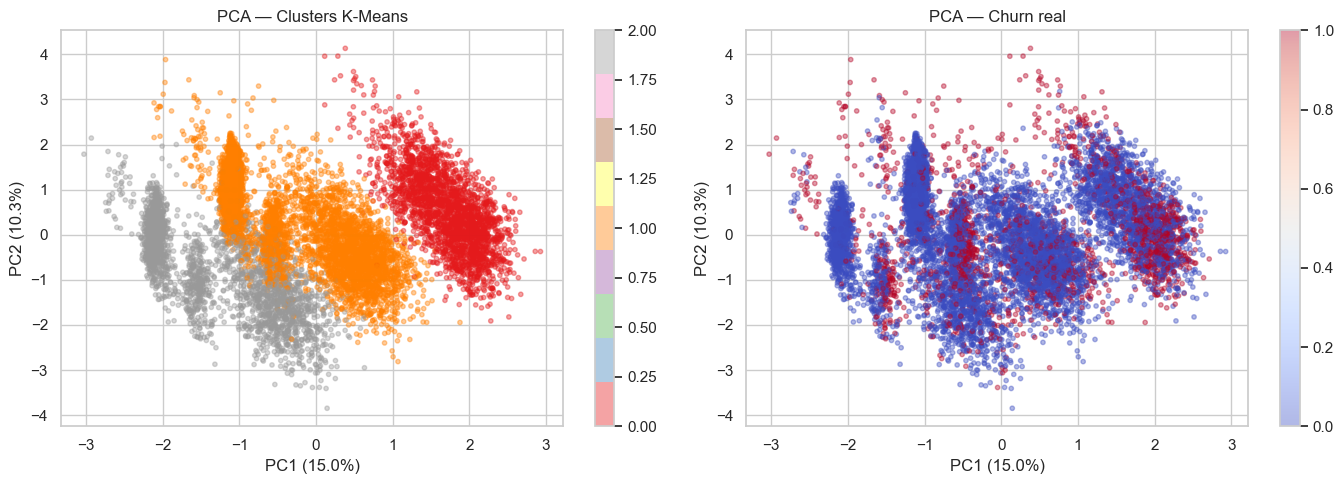

In [21]:
# Visualizar los clusters K-Means en el espacio reducido por PCA
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: clusters K-Means
scatter = axes[0].scatter(X_pca[:, 0], X_pca[:, 1],
                          c=clusters_kmeans, cmap='Set1',
                          alpha=0.4, s=10)
axes[0].set_title('PCA — Clusters K-Means')
axes[0].set_xlabel(f'PC1 (15.0%)')
axes[0].set_ylabel(f'PC2 (10.3%)')
plt.colorbar(scatter, ax=axes[0])

# Gráfico 2: churn real
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1],
                           c=y, cmap='coolwarm',
                           alpha=0.4, s=10)
axes[1].set_title('PCA — Churn real')
axes[1].set_xlabel(f'PC1 (15.0%)')
axes[1].set_ylabel(f'PC2 (10.3%)')
plt.colorbar(scatter2, ax=axes[1])

plt.tight_layout()
plt.show()

El gráfico izquierdo muestra los 3 clusters separados en 2 dimensiones.
Hay solapamiento entre ellos porque PCA solo captura el 25.4% de la información.

El gráfico derecho muestra el churn real.
El rojo no se concentra en ninguna zona específica — está mezclado con el azul en todas partes.

No se puede trazar una línea que separe a los que se van de los que se quedan.
El churn depende de combinaciones complejas de variables que solo un modelo matemático puede detectar.

### 5.2 t-SNE

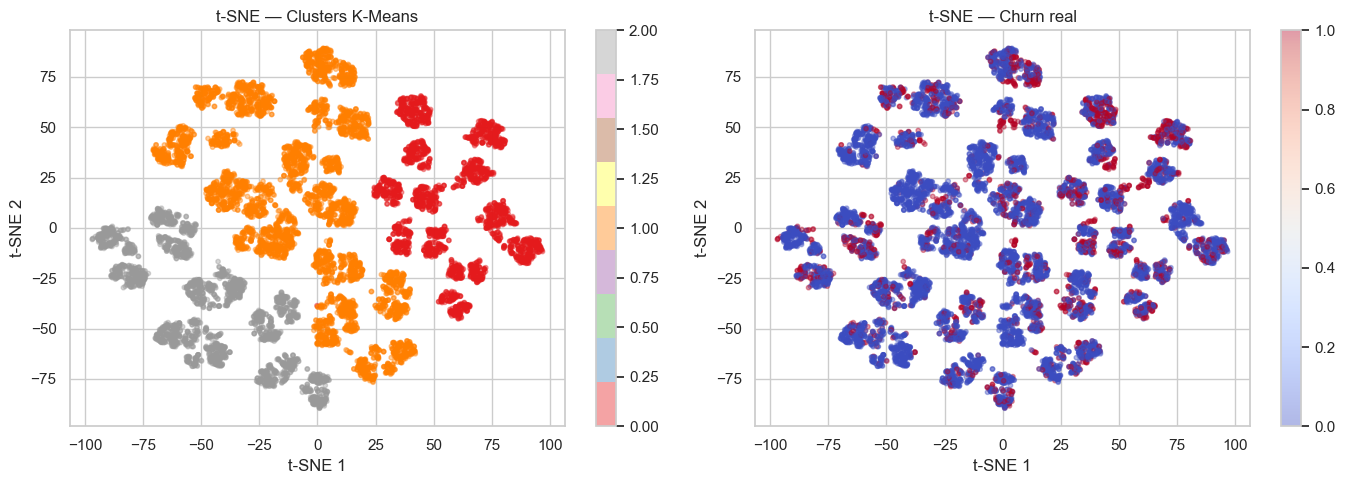

In [22]:
# Reducir 11 dimensiones a 2 con t-SNE — mejor para visualizar clusters que PCA
tsne = TSNE(n_components=2, random_state=42, 
            perplexity=30)  # controla cuántos vecinos considera cada punto
X_tsne = tsne.fit_transform(X_scaled)

# Visualizar los clusters K-Means y churn real en el espacio t-SNE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: clusters K-Means
scatter = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1],
                          c=clusters_kmeans, cmap='Set1',
                          alpha=0.4, s=10)
axes[0].set_title('t-SNE — Clusters K-Means')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')
plt.colorbar(scatter, ax=axes[0])

# Gráfico 2: churn real
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                           c=y, cmap='coolwarm',
                           alpha=0.4, s=10)
axes[1].set_title('t-SNE — Churn real')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
plt.colorbar(scatter2, ax=axes[1])

plt.tight_layout()
plt.show()

t-SNE muestra los mismos 3 clusters que PCA pero más separados y con subgrupos internos visibles.
Esos subgrupos son los perfiles específicos que encontró DBSCAN dentro de cada cluster.

En el gráfico de churn real el rojo sigue mezclado con el azul en todos los grupos.
La misma conclusión que PCA: el churn no tiene una zona geográfica clara.

t-SNE vs PCA:
- t-SNE muestra mejor la estructura local de los datos — clientes similares aparecen más cerca
- PCA es más rápido y se puede aplicar a clientes nuevos sin reentrenar
- t-SNE se usa solo para visualizar, PCA se usa también para alimentar otros modelos

## 6. Conclusiones

In [23]:
# Resumen de los hallazgos del Avance 3
print('=== Resumen Avance 3 ===')
print()
print('K-Means (K=3):')
print('  Cluster 0: 2.509 clientes, Balance $119k, churn 32.4% → ALTO RIESGO')
print('  Cluster 1: 5.014 clientes, Balance $62k,  churn 16.2% → BAJO RIESGO')
print('  Cluster 2: 2.477 clientes, Balance $61k,  churn 16.7% → BAJO RIESGO')
print()
print('DBSCAN:')
print('  Patrón encontrado: Balance alto + IsActiveMember=0 → churn hasta 78%')
print('  eps=1.5 fue el más informativo')
print()
print('Patrón común en ambos algoritmos:')
print('  Balance alto + cliente inactivo = mayor riesgo de churn')
print()
print('PCA: varianza explicada 25.4% en 2 componentes')
print('t-SNE: mejor separación visual de clusters que PCA')

=== Resumen Avance 3 ===

K-Means (K=3):
  Cluster 0: 2.509 clientes, Balance $119k, churn 32.4% → ALTO RIESGO
  Cluster 1: 5.014 clientes, Balance $62k,  churn 16.2% → BAJO RIESGO
  Cluster 2: 2.477 clientes, Balance $61k,  churn 16.7% → BAJO RIESGO

DBSCAN:
  Patrón encontrado: Balance alto + IsActiveMember=0 → churn hasta 78%
  eps=1.5 fue el más informativo

Patrón común en ambos algoritmos:
  Balance alto + cliente inactivo = mayor riesgo de churn

PCA: varianza explicada 25.4% en 2 componentes
t-SNE: mejor separación visual de clusters que PCA


Sin usar el churn para agrupar, ambos algoritmos llegaron a las mismas conclusiones que el EDA del Notebook 1 y los modelos del Notebook 2.

K-Means identificó 3 segmentos: el Cluster 0 con saldo alto concentra el doble de churn.

DBSCAN confirmó que la inactividad es el factor más crítico: churn hasta 78%.

Patrón común: clientes con Balance alto e IsActiveMember=0 son el mayor riesgo.

Para el banco esto es accionable: además de usar los modelos del Notebook 2 para predecir churn individualmente, puede diseñar estrategias específicas para los 2.509 clientes del Cluster 0 antes de que decidan irse.